# Single-cell RNA-seq analysis of interferon response in PBMCs

FARHAN Ishraq, 12th October 2026

----

## Background
This notebook displays a rudimentary analysis of scRNA sequencing data using the scverse Python tools (mainly Scanpy<sup>1</sup>). I used the processed dataset (GEO Accession GSE96583) from Kang _et al_.<sup>2</sup> This was a submission for a techincal assessment as part of a PhD application.

Kang et _al_<sup>3</sup> profiled peripheral blood mononuclear cells (PBMCs) from patients with systemic lupus erythematosus using droplet-based single-cell RNA-seq (10x Genomics). Two different aliquots of cells from each donor were taken: untreated (control) and stimluated with recombinant IFN-β for 6 hours. The samples were pooled and multiplexed with donor identity resolved by genotype-based demultiplexing (demuxlet). The study characterised cell-type-specific interferon responses and the genetic basis of expression variation.


The overall of this notebook is as follows:
1. Data Inspection
2. Normalisation
3. Differential Expression Analysis (naïve and pseudobulk) and GSEA

---
1. Wolf, F., Angerer, P. & Theis, F. SCANPY: large-scale single-cell gene expression data analysis. Genome Biol 19, 15 (2018). https://doi.org/10.1186/s13059-017-1382-0
2. Schumacher, Antonia; Heumos, Lukas (2022). Kang HM, Subramaniam M, Targ S, Nguyen M et al. 2017. figshare. Dataset. https://doi.org/10.6084/m9.figshare.19397624.v2
3. Kang, H., Subramaniam, M., Targ, S. et al. Multiplexed droplet single-cell RNA-sequencing using natural genetic variation. Nat Biotechnol 36, 89–94 (2018). https://doi.org/10.1038/nbt.4042

In [1]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pertpy as pt
import gseapy as gp

In [2]:
dataset = sc.read_h5ad("kang.h5ad") # memory mode since the filesize is not large

----
## Task 1 - Data Inspection

### 1
The dataset stored as an `AnnData` object contains 24673 (`n_obs`) cells and 15706 (`n_vars`) genes. There are no additional layers or `.raw`.

In [3]:
dataset

AnnData object with n_obs × n_vars = 24673 × 15706
    obs: 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters'
    var: 'name'
    obsm: 'X_pca', 'X_umap'
    layers: None (.X)

Within `.X`, raw counts are stored. We infer this from the fact that only non-negative integer values are present (not to be mistaken with the Integer datatype), and that sums of rows are not equal.

In [4]:
x = dataset.X
print("Max:", x.max(), " Min:",x.min())

y = x.rint() - x # round to nearest int and take difference
print("Number of non-integer elements:", y.size)

Max: 3828.0  Min: 0.0
Number of non-integer elements: 0


Histogram of total counts per cell:


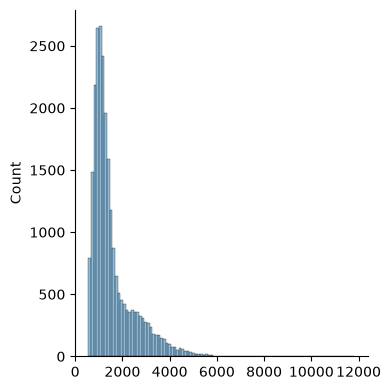

In [5]:
print("Histogram of total counts per cell:")
sns.displot(x.sum(1),  height=4, bins=100, legend=False)

### 2
`.var` stores the index of gene names while `.obs` stores the sample data. Inside `.obs`, the following columns encode:
- `cell_type`: cell type
- `label`: control (`ctrl`) or stimulated (`stim`)
- `replicate`: donor sample ID

In [6]:
dataset.var

,name
index,
AL627309.1,AL627309.1
RP11-206L10.2,RP11-206L10.2
RP11-206L10.9,RP11-206L10.9
FAM87B,FAM87B
LINC00115,LINC00115
...,...
C21orf58,C21orf58
PCNT,PCNT
DIP2A,DIP2A


In [7]:
obs = dataset.obs
obs

,nCount_RNA,nFeature_RNA,tsne1,tsne2,label,cluster,cell_type,replicate,nCount_SCT,nFeature_SCT,integrated_snn_res.0.4,seurat_clusters
index,,,,,,,,,,,,
AAACATACATTTCC-1,3017.0,877,-27.640373,14.966629,ctrl,9,CD14+ Monocytes,patient_1016,1704.0,711,1,1
AAACATACCAGAAA-1,2481.0,713,-27.493646,28.924885,ctrl,9,CD14+ Monocytes,patient_1256,1614.0,662,1,1
AAACATACCATGCA-1,703.0,337,-10.468194,-5.984389,ctrl,3,CD4 T cells,patient_1488,908.0,337,6,6
AAACATACCTCGCT-1,3420.0,850,-24.367997,20.429285,ctrl,9,CD14+ Monocytes,patient_1256,1738.0,653,1,1
AAACATACCTGGTA-1,3158.0,1111,27.952170,24.159738,ctrl,4,Dendritic cells,patient_1039,1857.0,928,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGCATGCCTGAA-2,1033.0,468,18.268321,1.058202,stim,6,CD4 T cells,patient_1244,1128.0,468,2,2
TTTGCATGCCTGTC-2,2116.0,819,-11.563067,2.574095,stim,4,B cells,patient_1256,1669.0,799,3,3
TTTGCATGCTAAGC-2,1522.0,523,25.142392,6.603815,stim,6,CD4 T cells,patient_107,1422.0,523,0,0


The dataset was originally pre-processed as a Seurat object.<sup>1</sup>
- `nCount_RNA` → number of molecules detected
- `nFeature_RNA` → number of genes detected
- `n[X]_SCT` → normalised X

1. Kang, H., Subramaniam, M., Targ, S. et al. Multiplexed droplet single-cell RNA-sequencing using natural genetic variation. Nat Biotechnol 36, 89–94 (2018). https://doi.org/10.1038/nbt.4042

Columns `integrated_snn_res.0.4` and `seurat_clusters` are identical

In [8]:
# returns blank DataFrame if no entries differ
dataset.obs["integrated_snn_res.0.4"].compare(dataset.obs["seurat_clusters"])

,self,other
index,,


### 3
The dataset contains data for the these cell types (with breakdown of quantities by condition (`label`)):  

In [9]:
print("Cell counts by cell type and condtion")
obs.groupby(["cell_type", "label"]).size()

Cell counts by cell type and condtion


cell_type          label
CD4 T cells        ctrl     5560
                   stim     5678
CD14+ Monocytes    ctrl     2932
                   stim     2765
B cells            ctrl     1316
                   stim     1335
NK cells           ctrl      855
                   stim      861
CD8 T cells        ctrl      811
                   stim      810
FCGR3A+ Monocytes  ctrl      520
                   stim      569
Dendritic cells    ctrl      258
                   stim      271
Megakaryocytes     ctrl       63
                   stim       69
dtype: int64

### 4
While the conditions are balanced in the dataset (see below for overall comparison, see above for breakdown within cell types), the classes themselves are not balanced. 

Megakaryocytes are rare classes, in comparison to the most common class CD4 T cells. Downstream statistics would mostly be biased to reflect that of more common classes (e.g. CD4 T cells), overshadowing statistics extracted from rarer classes (e.g. megakaryocytes) when data is aggregated (e.g during pseudobulking).

In cell-type standalone analyses, rarer classes would tend to have more noisier figures, especially if there are outlier cells. This may distort statistics where values from the few outlier cells dominate (e.g. fold change).

In [10]:
cell_type_sizes = obs.groupby('cell_type').size()
label_sizes = obs.groupby("label").size()

print("Control and stimulated cell samples are balanced overall with similar quantities\n", label_sizes)
print("\nCell types are not balanced\n", cell_type_sizes)

Control and stimulated cell samples are balanced overall with similar quantities
 label
ctrl    12315
stim    12358
dtype: int64

Cell types are not balanced
 cell_type
CD4 T cells          11238
CD14+ Monocytes       5697
B cells               2651
NK cells              1716
CD8 T cells           1621
FCGR3A+ Monocytes     1089
Dendritic cells        529
Megakaryocytes         132
dtype: int64


<Axes: >

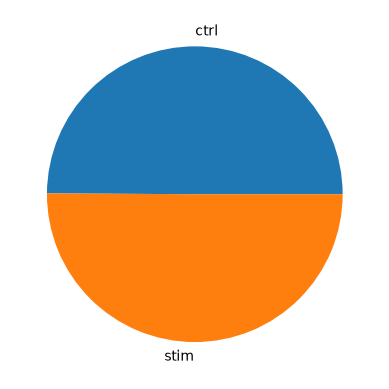

In [11]:
label_sizes.plot.pie()

<Axes: >

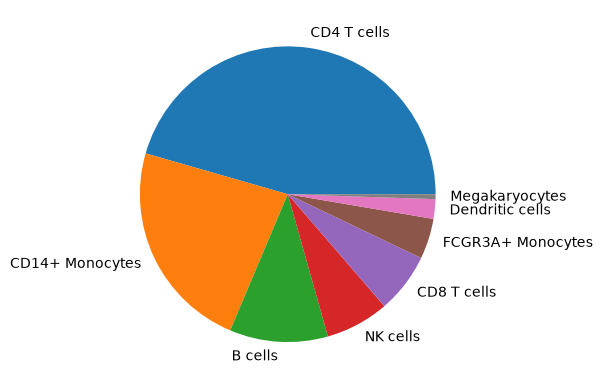

In [12]:
 cell_type_sizes.plot.pie()

### 5
The distributions of per-cell QC metrics reveals that there are greater counts for stimulated cells (see longer upper tail in left violin plots below), but overall, the distributions are similar.

In [13]:
## compute QC metrics into dataset
sc.pp.calculate_qc_metrics(dataset, percent_top=None,inplace=True,log1p=False)

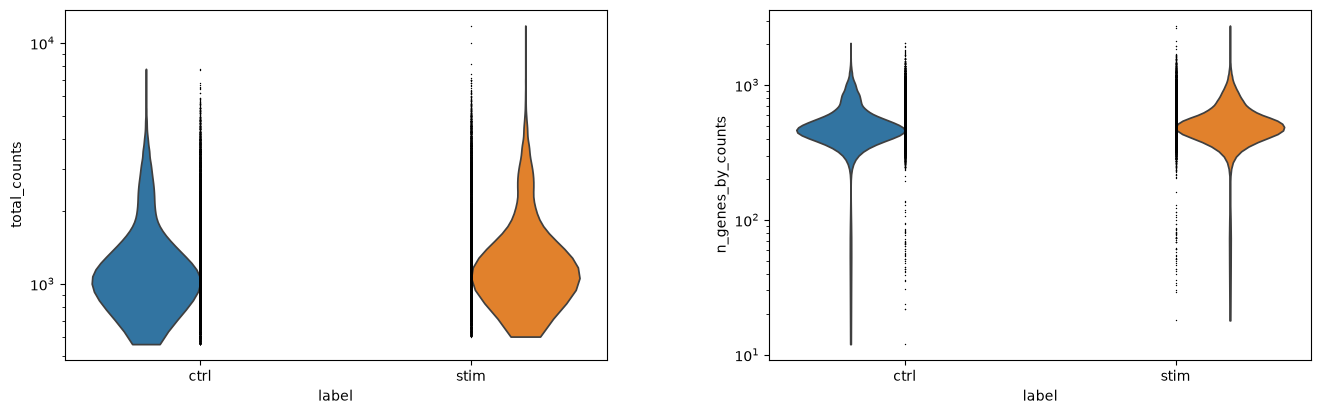

In [14]:
sc.pl.violin(dataset, ['total_counts', 'n_genes_by_counts'], groupby='label',
             jitter=False, log=True)

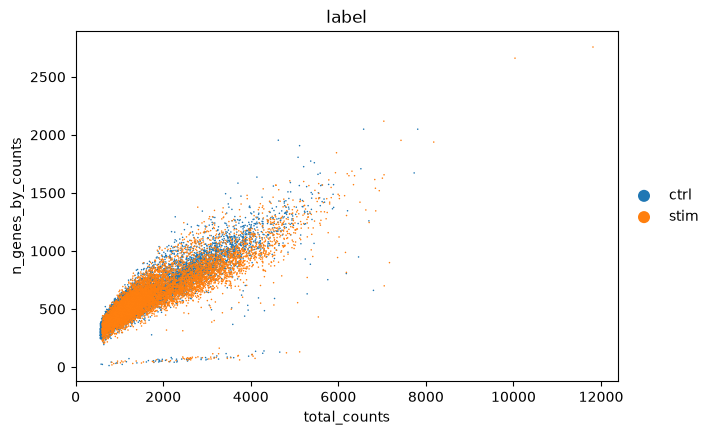

In [15]:
sc.pl.scatter(dataset, x="total_counts", y="n_genes_by_counts", color="label")

It appears that mitochondrial genes have been removed from the dataset, so % mitochondrial reads cannot be computed.

In [16]:
print("List of MT- genes in `.var`")

list(filter(lambda w: w.startswith("MT-"), dataset.var['name']))

List of MT- genes in `.var`


[]

### 6
Plotting the UMAP reveals that the cells are separated by cell type, but are not resolved by condition.

Dendritic cells, CD14+ monocytes and FCGR3A+ monocytes form their own island. CD4 T cells, CD8 T cells and NK cells form their own island. B cells and megakaryocytes form their own islands respectively.

In [17]:
# compute UMAP for different k
for k in [15, 30, 60]:
    sc.pp.neighbors(dataset, n_neighbors=k, 
                    key_added='X_neighbors_'+str(k))
    sc.tl.umap(dataset, neighbors_key='X_neighbors_'+str(k), 
               key_added='umap_'+str(k))

k=15


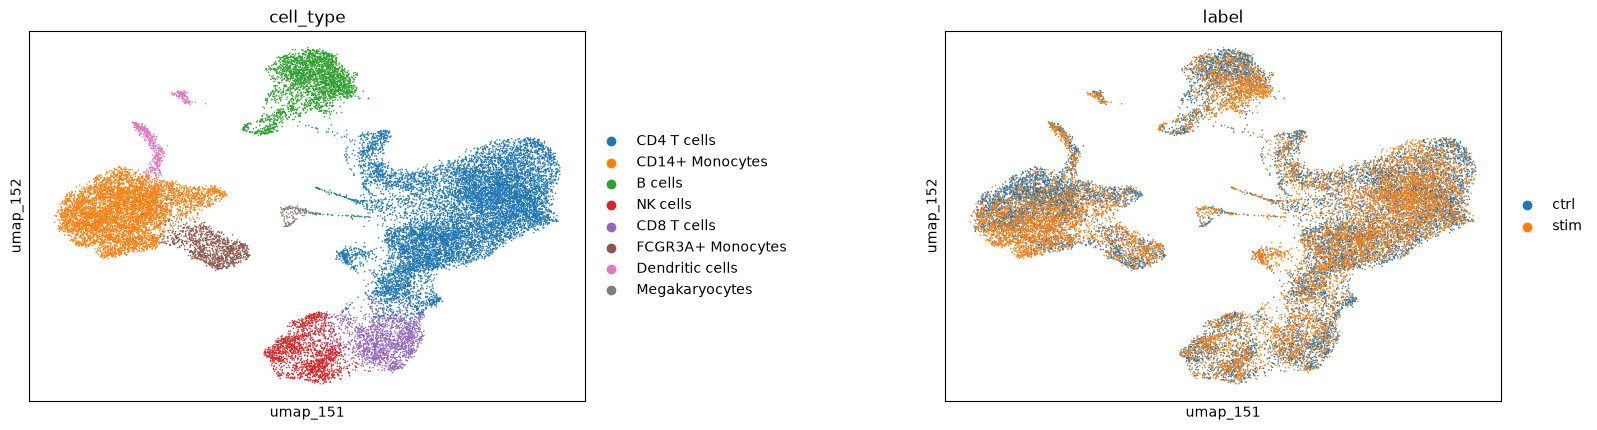

In [18]:
print("k=15")
sc.pl.embedding(dataset, 'umap_15',
                neighbors_key='X_neighbours_15', color=['cell_type', 'label'], 
                wspace=0.5)

k=30


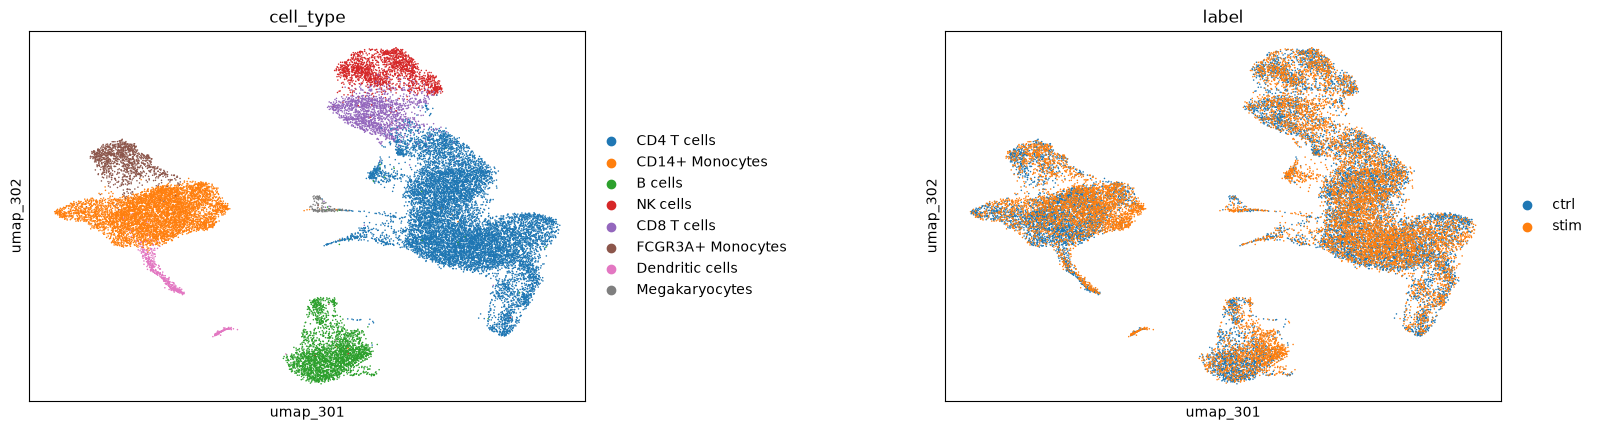

In [19]:
print("k=30")
sc.pl.embedding(dataset, 'umap_30',
                neighbors_key='X_neighbours_30', color=['cell_type', 'label'], 
                wspace=0.5)

k=60


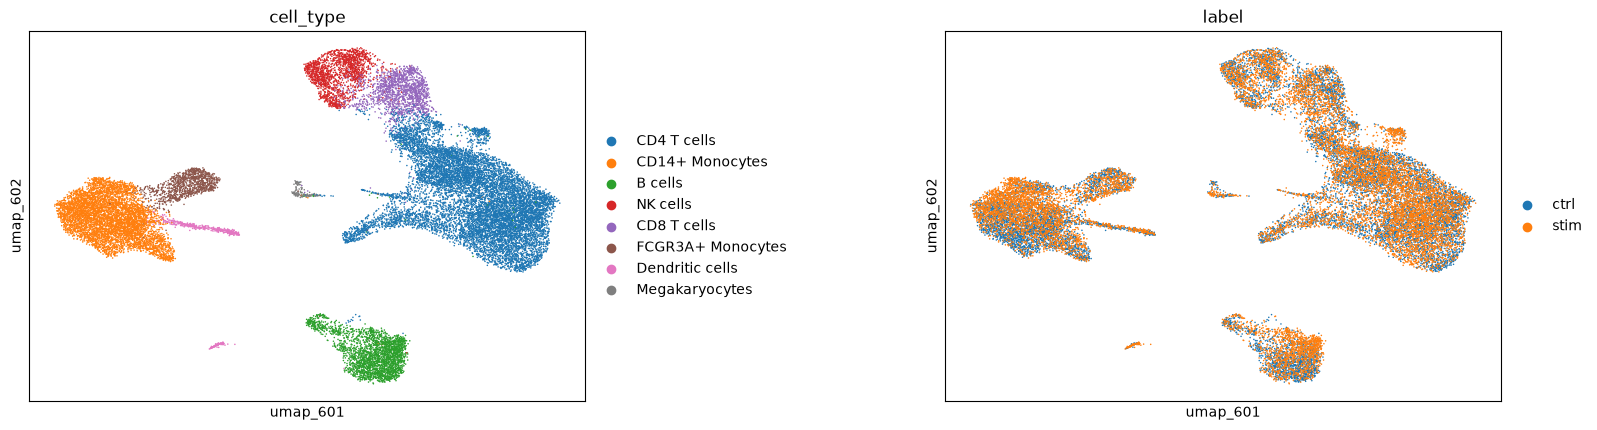

In [20]:
print("k=60")
sc.pl.embedding(dataset, 'umap_60',
                neighbors_key='X_neighbours_60', color=['cell_type', 'label'], 
                wspace=0.5)

### 7

Only two cell types have different names in the original paper and dataset. The associated paper refers to CD14+ monocytes in the dataset as CD14+CD16- monocytes while FCGR3A+ monocytes in the dataset is referred to as CD14+CD16+ monocytes in the paper. FCGR3A is synonymous to the CD16 surface marker. 

----
## Task 2 - Normalisation

### 1 
Normalisation has not been applied to the data.

Had it been otherwise, normalisation factors (supplied by the normalisation function) should also be present in the AnnData object to reverse the normalisation. DESeq2 analysis (Task 3.2) requires raw counts

### 2
Since later analyses (Task 3.2) require raw counts, library-size normalised counts are stored in the `lib_norm` layer to not overwrite raw counts in `.X`

Log transformed values are stored in the `log1p` layer.

In [21]:
# library-size normalisation
dataset.layers["lib_norm"] = sc.pp.normalize_total(dataset, 
                                                   target_sum=10_000, 
                                                   key_added="norm_factor", 
                                                   inplace=False)['X']

# log1p transformation
dataset.layers["log1p"] = sc.pp.log1p(dataset.layers['lib_norm'], copy=True) 

### 3
Top 1000 highly variable genes were taken. 

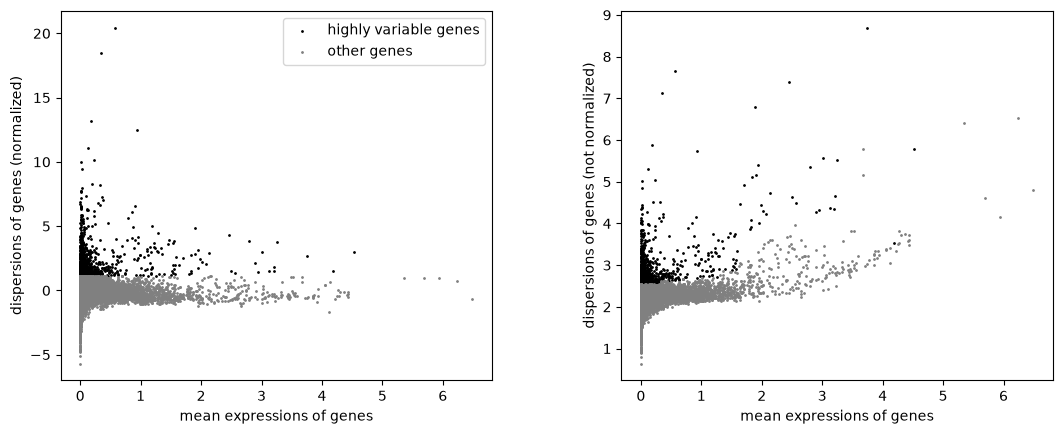

In [22]:
sc.pp.highly_variable_genes(dataset, layer="log1p", n_top_genes=1000)
sc.pl.highly_variable_genes(dataset)

In [23]:
sc.pp.pca(dataset, layer='log1p', mask_var='highly_variable', 
          key_added='X_pca_log')

# builid kNN graphs and compute UMAPs
for k in [15, 30, 60]:
    sc.pp.neighbors(dataset, n_neighbors=k, use_rep='X_pca_log', 
                    key_added='X_neighbors_log_'+str(k))
    sc.tl.umap(dataset, neighbors_key='X_neighbors_log_'+str(k), 
               key_added='umap_log_'+str(k))

After normalisation, the UMAP plots shows better resolution between both cell type and condition. However, megakaryocytes remain to not be resolved by condition.

Cells continue to share islands before and after normalisation. 

k=15


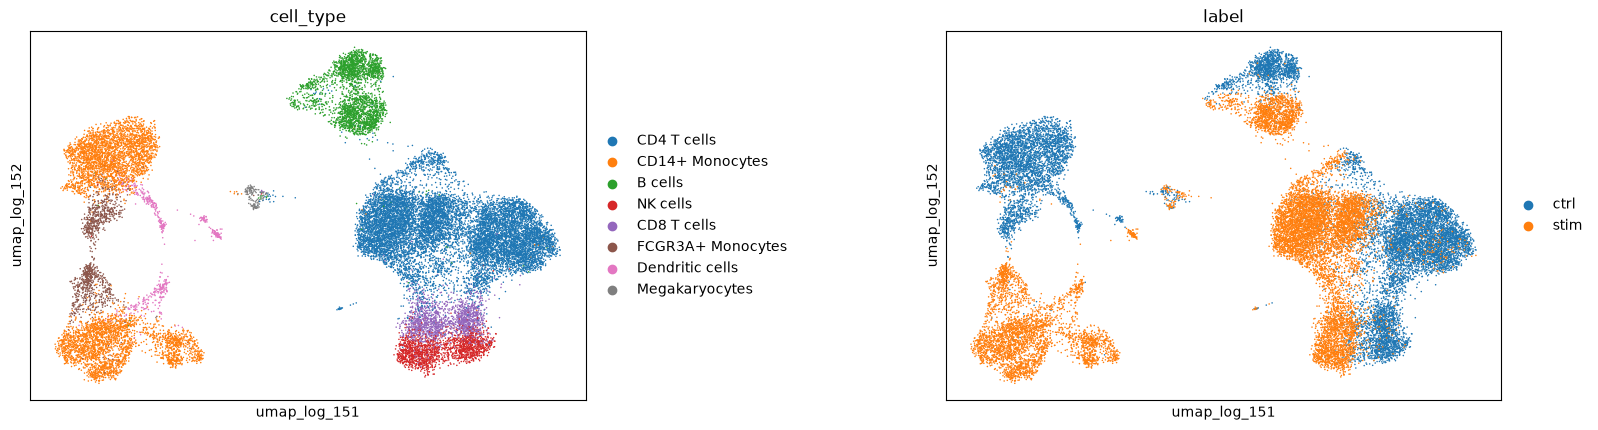

In [24]:
print("k=15")
sc.pl.embedding(dataset, 'umap_log_15', layer="log1p", 
                neighbors_key='X_neighbours_log_15', color=['cell_type', 'label'], 
                wspace=0.5)

k=30


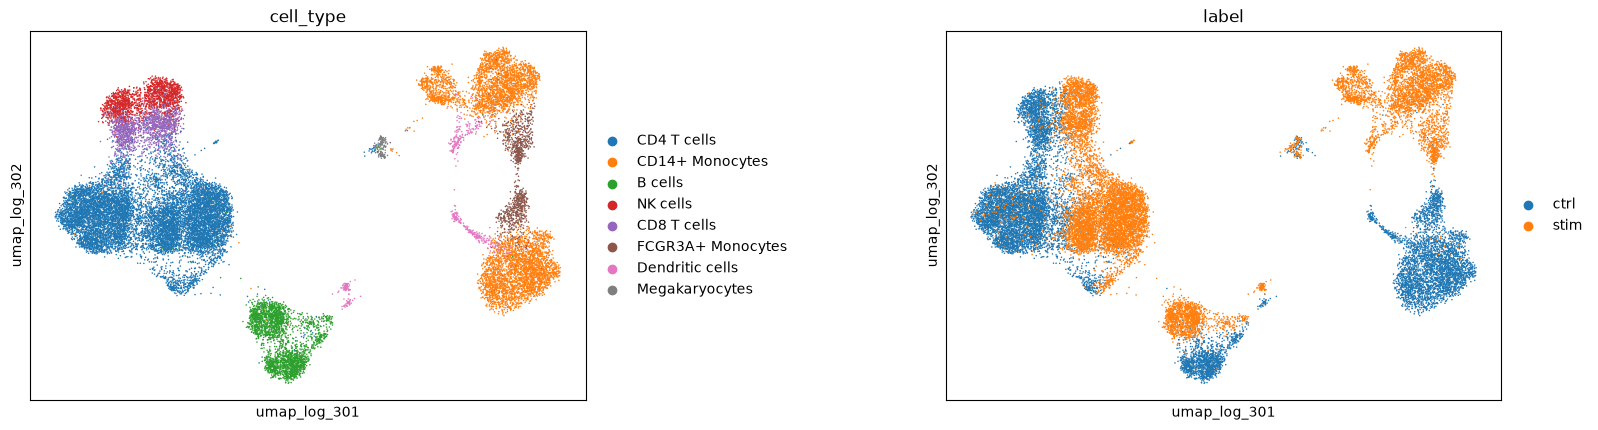

In [25]:
print("k=30")
sc.pl.embedding(dataset, 'umap_log_30', layer="log1p", 
                neighbors_key='X_neighbours_log_30', color=['cell_type', 'label'], 
                wspace=0.5)

k=60


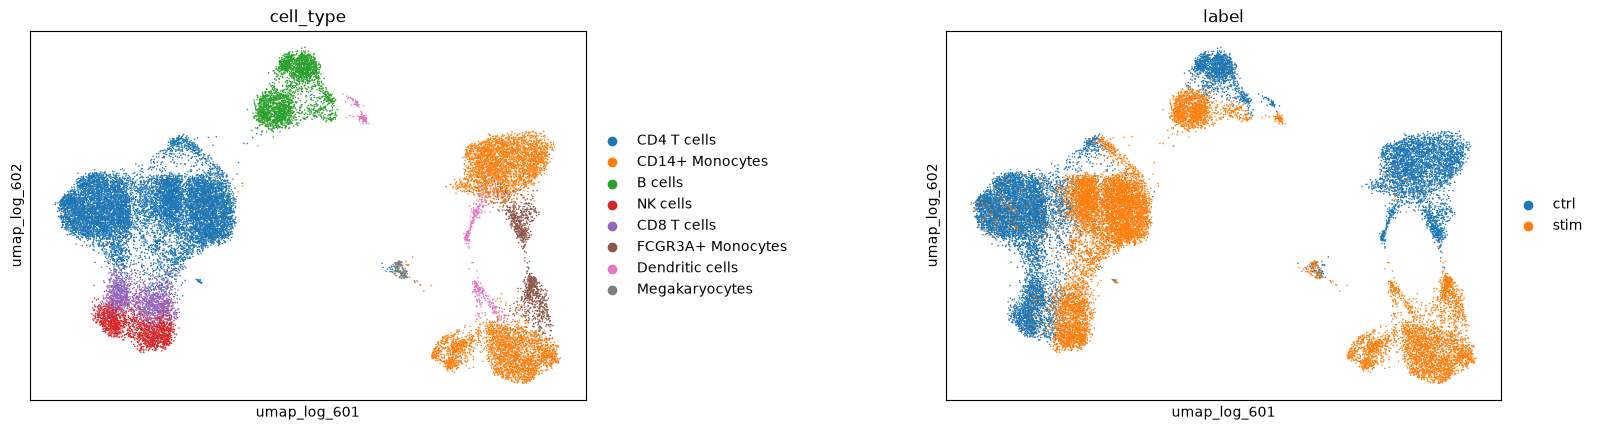

In [26]:
print("k=60")
sc.pl.embedding(dataset, 'umap_log_60', layer="log1p", 
                neighbors_key='X_neighbours_log_60', color=['cell_type', 'label'], 
                wspace=0.5)

### 4 - Why normalise and log-transform? What are their limitations?
Other than intrinsic differences, differences in gene expression recorded may be a result of technical issues that may impact sequencing depth and capture efficiency. This means that computation directly based in raw counts would not account for  confounding factors arising from sampling methodology that do not reflect real biology.

Log-tranformation reduces the numerical scale of count values, transforming multiplicative changes to linear additive changes. This is significant with respect to the mean-variation relationship (see right HVG plot in Task 2.3, reproduced below) where there is a positive relation between mean and variance. Normalisation helps in alleviate this corelation between mean and variance for subsequent analyses (left HVG plot)

While applying this transformation will account for highly expressed genes to a certain extent,  this transformation is limited due to log(x) being undefined at x = 0. This requires adding an arbitrary pseudocount (C) into log(x + C) which distorts  the distribution for small x's. This is particularly problematic for lowly expressed genes where the final value is mostly reflective of C rather than x, as well as during visualiation where single-cell datasets often feature zeros. 

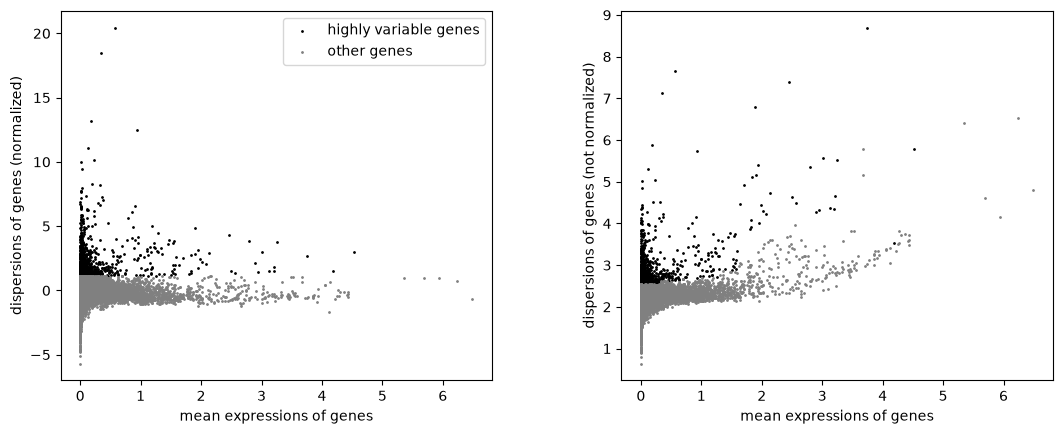

In [27]:
sc.pl.highly_variable_genes(dataset)

This method of normalisation applies the same transformation on cell data regardless of which donor or replicate it is collected from. Since donor or batch effects impact different genes by different amounts, they cannot be removed in this way with a common scaling factor across all donors and cells. In this dataset, donor or batch effects needs to be paid attention to because in the UMAP below there is dominance of `patient_1016` within the CD8 T cell region, and of `patient_1039` in the megakaryocyte region.

Despite the benefits of normalisation, some analyses require raw counts such as pseudobulking (Task 3.2) and highly variable gene selection using `seurat_v3`.


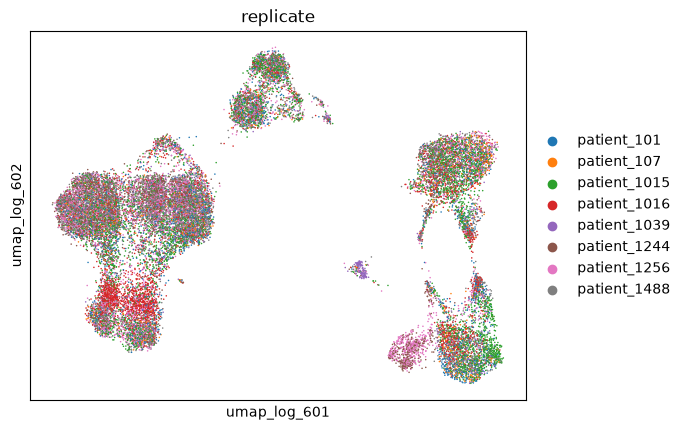

In [28]:
sc.pl.embedding(dataset, 'umap_log_60',
                neighbors_key='X_neighbours_log_60', color=['replicate'], 
                wspace=0.5)

----
## Task 3 - Differential Expression

### 1 - Naïve approach
I report the top 20 genes based on the z score.

In [29]:
cd14 = dataset[dataset.obs["cell_type"] == "CD14+ Monocytes"].copy()

In [30]:
sc.tl.rank_genes_groups(cd14, 
                        layer="log1p", 
                        groupby="label", 
                        groups=["stim"],
                        reference="ctrl",
                        method='wilcoxon', 
                        key_added="CD14+ Monocytes")

In [31]:
cd14_gene_rank = sc.get.rank_genes_groups_df(cd14, group='stim', key="CD14+ Monocytes")

In [32]:
cd14_gene_rank.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,ISG15,65.258301,8.788952,0.0,0.0
1,IFITM3,64.862793,6.379553,0.0,0.0
2,ISG20,64.778404,6.688002,0.0,0.0
3,APOBEC3A,64.438072,6.637323,0.0,0.0
4,TNFSF10,63.568222,8.378161,0.0,0.0
5,LY6E,63.471783,6.557436,0.0,0.0
6,IFIT3,63.412712,8.139936,0.0,0.0
7,CXCL10,63.315266,10.479670,0.0,0.0
8,RSAD2,63.072002,8.453033,0.0,0.0
9,IFI6,62.254364,5.239681,0.0,0.0


Though most of the top 20 genes above appears in the paper's top 20 list (Supplementary Table 1) for B cells (CD8), my ranking of ISGs do not match that of the paper.

### 2 - Pseudobulk Approach

The Pertpy package<sup>1</sup> was used for differential expression calculation




1. Heumos, L., Ji, Y., May, L. et al. Pertpy: an end-to-end framework for perturbation analysis. Nat Methods 23, 350–359 (2026). https://doi.org/10.1038/s41592-025-02909-7

In [33]:
## add column to collect replicate X condition
dataset.obs["pb_sample"] = pd.Categorical(
    f"{rep}_{l}" for rep, l in zip(
        dataset.obs["replicate"],
        dataset.obs["label"]
    )
)

## aggegrate raw counts
ds_pb = pt.tl.PseudobulkSpace().compute(dataset, 
                                        target_col="pb_sample",
                                        groups_col="cell_type", 
                                        mode="sum")

In [34]:
## perform DESeq2 on B cells

cd14_pb = ds_pb[ds_pb.obs["cell_type"] == "CD14+ Monocytes"].copy()
pds2 = pt.tl.PyDESeq2(adata=cd14_pb, layer="sum",design='~ replicate + label')
pds2.fit()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 2.34 seconds.

Fitting dispersion trend curve...
/home/i/MARENTAKEHOME/mrn_venv/lib/python3.12/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 3.70 seconds.

Fitting LFCs...
... done in 3.51 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [35]:
cd14_res_df = pds2.test_contrasts(pds2.contrast(
    column="label",
    baseline="ctrl",
    group_to_compare="stim")
)

Running Wald tests...


Log2 fold change & Wald test p-value, contrast vector: [0. 0. 0. 0. 0. 0. 0. 0. 1.]
                baseMean  log2FoldChange     lfcSE      stat        pvalue  \
index                                                                        
AL627309.1      0.000000             NaN       NaN       NaN           NaN   
RP11-206L10.2   0.048279       -0.009587  3.307776 -0.002898  9.976875e-01   
RP11-206L10.9   0.038819        0.007330  3.307785  0.002216  9.982319e-01   
FAM87B          0.064274        0.686369  3.307617  0.207512  8.356102e-01   
LINC00115       0.762520       -0.111458  0.830292 -0.134239  8.932135e-01   
...                  ...             ...       ...       ...           ...   
C21orf58        0.119023        0.014851  1.478173  0.010047  9.919839e-01   
PCNT            0.497204       -0.241504  0.964133 -0.250488  8.022098e-01   
DIP2A           3.807076       -0.541878  0.432249 -1.253624  2.099787e-01   
S100B           0.173298       -0.020206  1.451102 -0.0139

... done in 1.17 seconds.



In [36]:
cd14_res_df.head(20)

,variable,baseMean,log_fc,lfcSE,stat,p_value,adj_p_value,contrast
0,H3F3B,4800.830855,1.149257,0.044893,25.599679,1.538156e-144,1.423409e-140,None
1,DYNLT1,959.107510,2.730310,0.119642,22.820635,2.861159e-115,1.323858e-111,None
2,IL1RN,919.051582,6.738308,0.296161,22.752150,1.366374e-114,4.214810e-111,None
3,TMSB10,2674.385519,2.245092,0.099302,22.608754,3.554312e-113,8.222901e-110,None
4,MYL12A,1236.152213,1.971076,0.088067,22.381615,5.945128e-111,1.100324e-107,None
5,NAGK,240.944899,2.465612,0.110873,22.238141,1.469185e-109,2.265973e-106,None
6,CCL8,7422.412773,9.887073,0.458846,21.547712,5.562867e-103,7.354110e-100,None
7,TMEM50A,378.695904,1.766456,0.083063,21.266503,2.319411e-100,2.682979e-97,None
8,HSPB1,683.540640,3.093035,0.146506,21.111944,6.177835e-99,6.352188e-96,None
9,IFITM2,501.270229,4.842859,0.231866,20.886488,7.105697e-97,6.575612e-94,None


Similarly, the rankings do not match those in Task 3.1 or in the paper despite matching genes within the top 20.

### 3 - Comparasion of naïve and pseudobulk approaches
Taking adjusted-p < 0.05 and logFC > 1 as significant, the two methods give out two different numbers of significant genes.

In [37]:
cd14_sig_gene_rank = cd14_gene_rank[(cd14_gene_rank['pvals_adj']<0.05) & (cd14_gene_rank['logfoldchanges']>1)]
cd14_sig_res_df = cd14_res_df[(cd14_res_df['adj_p_value']<0.05) & (cd14_res_df['log_fc']>1)]

print("Number of significant genes in 3.1: ", len(cd14_sig_gene_rank))
print("Number of significant genes in 3.2: ", len(cd14_sig_res_df))

Number of significant genes in 3.1:  492
Number of significant genes in 3.2:  1188


There are 492 genes common to both methods. Furthermore, comparing their adjusted p-values from the two approaches reveals that the naïve approach tends to inflate significance (see below). 

This is a result of treating cells as independent replicates since here donor-specific effects are co-opted into calculations for condition effects (also see discussion in Task 2.4). The true unit of replication is the donor sample since cells from a given donor are not indepedent while cells from different donors are independent.

Significant gene overlap:  492


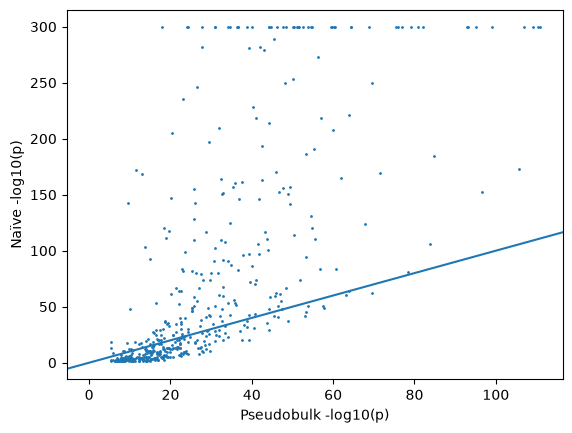

In [38]:
cd14_sig_overlap = set(cd14_sig_gene_rank['names']) & set(cd14_sig_res_df.loc[cd14_sig_res_df["adj_p_value"].notna(), "variable"])
print("Significant gene overlap: ", len(cd14_sig_overlap))

# plot adjusted p-values from naïve approach vs pseudobulking
naive = cd14_sig_gene_rank.set_index("names").loc[list(cd14_sig_overlap)]
pb = cd14_sig_res_df.set_index("variable").loc[list(cd14_sig_overlap)]

plt.scatter(-np.log10(pb["adj_p_value"]), -np.log10(naive["pvals_adj"].clip(lower=1e-300)), s=1)
plt.xlabel("Pseudobulk -log10(p)")
plt.ylabel("Naïve -log10(p)")
plt.axline((0, 0), slope=1)

### 4

The pseudobulk analysis was also performed on NK and B cells.

In [39]:
## perform pseudobulk analysis for B cells

b_pb = ds_pb[ds_pb.obs["cell_type"] == "B cells"].copy()
pds2 = pt.tl.PyDESeq2(adata=b_pb, layer="sum",design='~ replicate + label')
pds2.fit()

b_res_df = pds2.test_contrasts(pds2.contrast(
    column="label",
    baseline="ctrl",
    group_to_compare="stim")
)
b_sig_res_df = b_res_df[(b_res_df['adj_p_value']<0.05) & (b_res_df['log_fc']>1)]

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.59 seconds.

Fitting dispersion trend curve...
... done in 0.26 seconds.

Fitting MAP dispersions...
... done in 2.79 seconds.

Fitting LFCs...
... done in 3.56 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value, contrast vector: [0. 0. 0. 0. 0. 0. 0. 0. 1.]
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
index                                                                    
AL627309.1      0.000000             NaN       NaN       NaN       NaN   
RP11-206L10.2   0.035965       -0.497588  3.308442 -0.150400  0.880449   
RP11-206L10.9   0.074707       -0.508938  3.308099 -0.153846  0.877731   
FAM87B          0.033186       -0.510912  3.308012 -0.154447  0.877257   
LINC00115       0.316982        0.209619  2.075858  0.100979  0.919567   
...                  ...             ...       ...       ...       ...   
C21orf58        0.241819       -0.831465  3.279034 -0.253570  0.799828   
PCNT            0.656133       -0.189841  1.254088 -0.151378  0.879678   
DIP2A           0.772093       -0.574915  0.893147 -0.643696  0.519773   
S100B           0.074707       -0.508938  3.308099 -0.153846  0.877731   
PRMT2          10.424279    

... done in 0.93 seconds.



In [40]:
## perform pseudobulk analysis for NK cells

nk_pb = ds_pb[ds_pb.obs["cell_type"] == "NK cells"].copy()
pds2 = pt.tl.PyDESeq2(adata=nk_pb, layer="sum",design='~ replicate + label')
pds2.fit()

nk_res_df = pds2.test_contrasts(pds2.contrast(
    column="label",
    baseline="ctrl",
    group_to_compare="stim")
)
nk_sig_res_df = nk_res_df[(nk_res_df['adj_p_value']<0.05) & (nk_res_df['log_fc']>1)]

Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.38 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 2.47 seconds.

Fitting LFCs...
... done in 3.53 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value, contrast vector: [0. 0. 0. 0. 0. 0. 0. 0. 1.]
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
index                                                                    
AL627309.1      0.000000             NaN       NaN       NaN       NaN   
RP11-206L10.2   0.000000             NaN       NaN       NaN       NaN   
RP11-206L10.9   0.087344        0.590296  3.276839  0.180142  0.857041   
FAM87B          0.000000             NaN       NaN       NaN       NaN   
LINC00115       0.241038        0.293371  3.208030  0.091449  0.927136   
...                  ...             ...       ...       ...       ...   
C21orf58        0.135915       -0.431054  3.252973 -0.132511  0.894580   
PCNT            0.463564       -0.585416  1.315410 -0.445045  0.656288   
DIP2A           1.369035       -0.458218  0.775379 -0.590961  0.554547   
S100B           0.669795       -0.818166  1.474561 -0.554854  0.578995   
PRMT2          16.580729    

... done in 0.91 seconds.



CD14+ Monocytes
NaNs encountered, dropping rows with NaNs


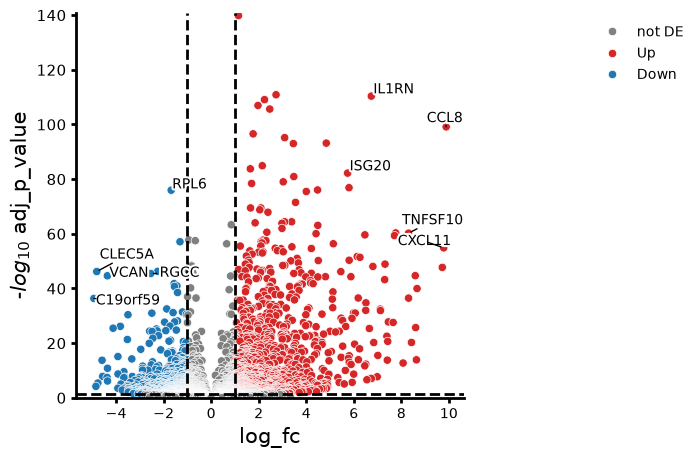

In [41]:
print("CD14+ Monocytes")
pds2.plot_volcano(cd14_res_df, log2fc_threshold=1)

B cells
NaNs encountered, dropping rows with NaNs


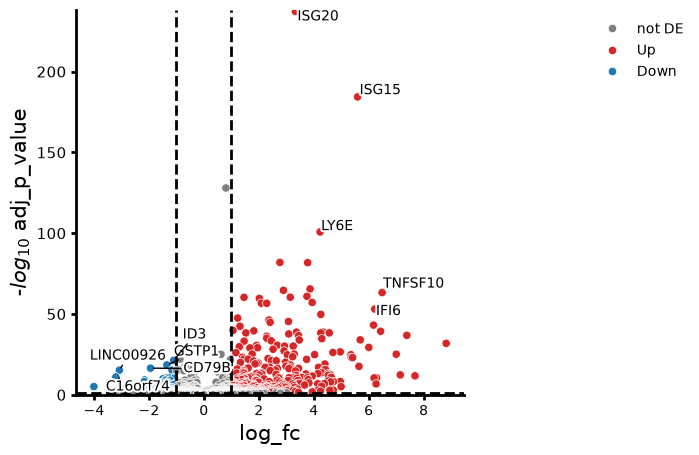

In [42]:
print("B cells")
pds2.plot_volcano(b_res_df, log2fc_threshold=1)

NK cells
NaNs encountered, dropping rows with NaNs


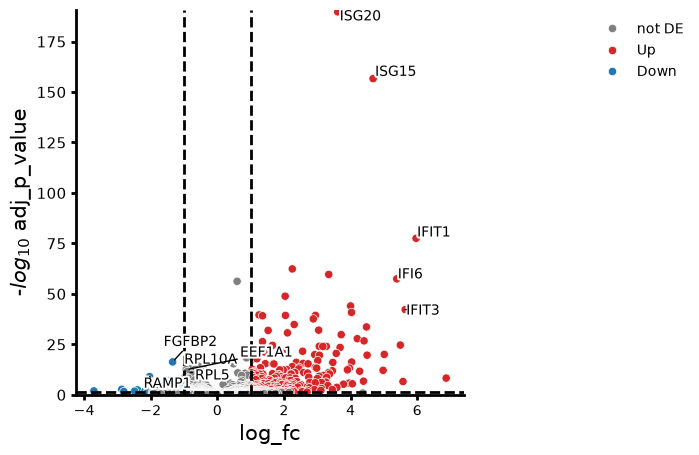

In [43]:
print("NK cells")
pds2.plot_volcano(nk_res_df, log2fc_threshold=1)

In [44]:
# combine DEs
all_res_df = {
    "CD14+ Monocytes": cd14_sig_res_df,
    "B cells": b_sig_res_df,
    "NK cells": nk_sig_res_df}

# keep only top 20 genes from each cell type
de = pd.concat(
    [df.head(20).assign(cell_type=ct) for ct, df in all_res_df.items()],
    ignore_index=True,
)

# trim down to only log_fc
lfc = de.pivot(
    index="variable",
    columns="cell_type",
    values="log_fc",
)

The heatmap below shows that some ISGs are:
- shared across the three cell types: DYNLT1, IRF7, ISG20, MYL12A, PLSCR1, TMSB10
- some are shared across two cell types:
    - B + CD14: IFITM2
    - B + NK: BST2, ISG15
    - CD14 + NK: OASL, and
- some are cell-type specific

Blank/white slots indicate null values in that cell type's sampling

Heatmap of ISG expression (log_fc) of top 20 genes


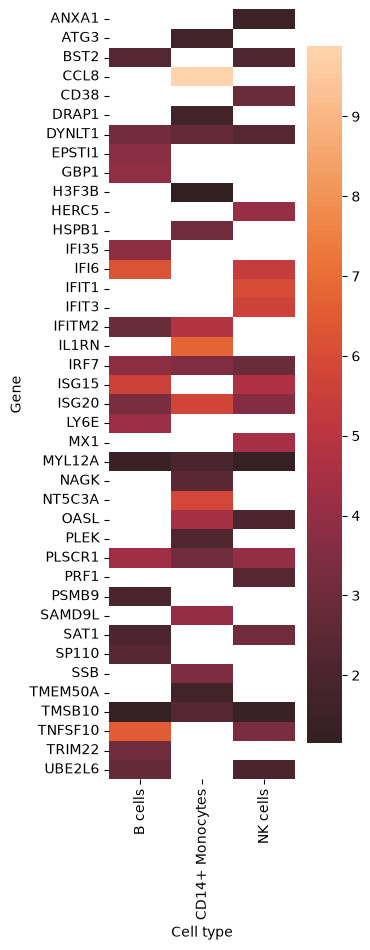

In [45]:
print("Heatmap of ISG expression (log_fc) of top 20 genes")
plt.figure(figsize=(3, 10))
sns.heatmap(lfc, center=0, xticklabels=True, yticklabels=True)
plt.xlabel("Cell type")
plt.ylabel("Gene")

plt.show()

### 5 - GSEA
Preranked GSEA (with GSEApy<sup>1</sup>) was performed on the three cell types with the MSigDB Hallmark gene sets. All three cell type consistently showed enrichment of Interferon Gamma Response (IGR) and Interferon Alpha Response (IAR) gene sets(ranked 1 and 2, respectively). Both terms also had a FDR value of 0.0 across cell types.

In CD14+ Monocytes, the IGR term (NES = 2.674664) and the IAR term (NES = 2.647622) were concentrated among the upregulated genes in stimulated cells. Lead genes in both terms include IFITM2, ISG20, IRF7, PLSCR1, OASL, SAMD9L and NMI. There is also lead gene overlap in the other two cell types, suggesting that there may not necessarily be a separate Type II interferon response in this instance. In fact, they share a common JAK1 kinase activation pathway ( further discussed below).<sup>2</sup>

In contrast, Oxidative Phosphorylation (NES = -1.961727, FDR = 0.0) and Myc Targets V1 (NES = -1.961727, FDR = 0.0) were negatively enriched. Increases in oxidative phosphorylation in non-phagocytic macrophages is a known metabolic change in response to IFN-β,<sup>3</sup> whereas it suppresses c-myc mRNA expression<sup>4</sup>.


1. Zhuoqing Fang, Xinyuan Liu, Gary Peltz, GSEApy: a comprehensive package for performing gene set enrichment analysis in Python, Bioinformatics, 2022;, btac757, https://doi.org/10.1093/bioinformatics/btac757
2. Wen, C., Lan, Q., Wang, Y., Ni, Y., Wong, A. S. T., & Liu, D. (2025). Interferon signaling pathways in health and disease. Molecular biomedicine, 6(1), 135. https://doi.org/10.1186/s43556-025-00381-5
3. Kumaran Satyanarayanan, S., El Kebir, D., Soboh, S. et al. IFN-β is a macrophage-derived effector cytokine facilitating the resolution of bacterial inflammation. Nat Commun 10, 3471 (2019). https://doi.org/10.1038/s41467-019-10903-9
4. Sarkar, D., Park, E. & Fisher, P. Defining the mechanism by which IFN-β dowregulates c-myc expression in human melanoma cells: pivotal role for human polynucleotide phosphorylase (hPNPaseold-35). Cell Death Differ 13, 1541–1553 (2006). https://doi.org/10.1038/sj.cdd.4401829

In [46]:
print("GSEA results for CD14+ Monocytes")
cd14_res = gp.prerank(rnk=cd14_res_df[['variable', 'stat']], gene_sets="MSigDB_Hallmark_2020")
cd14_res.res2d.head(5)

2026-10-12 11:32:54,551 [WARNING] Input gene rankings contains NA values(gene name and ranking value), drop them all!


GSEA results for CD14+ Monocytes


2026-10-12 11:32:54,582 [WARNING] Duplicated values found in preranked stats: 14.15% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Interferon Gamma Response,0.868459,2.656535,0.0,0.000000,0.000,138/193,6.72%,IFITM2;ISG20;IRF7;PLSCR1;OASL;SAMD9L;NMI;SOCS1...
1,prerank,Interferon Alpha Response,0.926778,2.599895,0.0,0.000000,0.000,84/94,5.02%,IFITM2;ISG20;IRF7;PLSCR1;OASL;SAMD9L;NMI;IFIT3...
2,prerank,Oxidative Phosphorylation,-0.538393,-2.018235,0.0,0.000000,0.000,94/180,18.25%,ATP6V0B;NDUFA4;NDUFAB1;UQCRC1;SLC25A5;TIMM13;C...
3,prerank,Myc Targets V1,-0.522671,-1.934481,0.0,0.000000,0.000,121/191,18.47%,RPL6;RPS3;RPL14;RPLP0;RPS6;NDUFAB1;PABPC1;RPS2...
4,prerank,Complement,0.622713,1.869619,0.0,0.000265,0.001,70/167,11.83%,PLEK;IRF7;PLSCR1;HSPA1A;CTSC;LYN;IRF2;CASP4;PS...


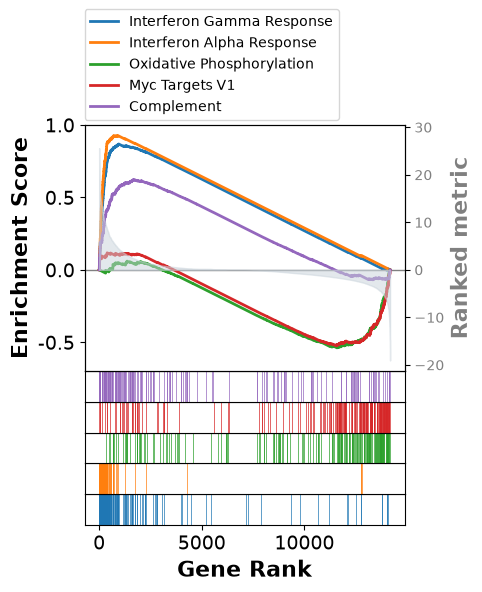

In [47]:
term = cd14_res.res2d.Term
axs = cd14_res.plot(terms=term[:5])

In these three cells, it is noted that Inflammatory Response, Complement and IL-6/JAK/STAT3 Signaling terms appear in the GSEA results. It is known that IFN-β plays a role in inflammation,<sup>1</sup> for which the complement system is a mediator.<sup>2</sup> Responses to interferons, as cytokines, in fact are transduced by the JAK-STAT signaling pathway.<sup>3</sup> The results from NK and B cells also display Apoptosis which is line with known biology of IFN-β inducing apoptosis in various cells.<sup>4,5<sup>


1. Kopitar-Jerala N (2017) The Role of Interferons in Inflammation and Inflammasome Activation. Front. Immunol. 8:873. https://doi.org/10.3389/fimmu.2017.00873
2. Janžič L and Kouter K (2026) Complement and inflammasome crosstalk in chronic inflammation. Front. Immunol. 17:1778759. https://doi.org/10.3389/fimmu.2026.1778759
3. Schindler, C., & Plumlee, C. (2008). Inteferons pen the jak–stat pathway. Seminars in Cell & Developmental Biology, 19(4), 311–318. https://doi.org/10.1016/j.semcdb.2008.08.010
4. Kumaran Satyanarayanan, S., El Kebir, D., Soboh, S. et al. IFN-β is a macrophage-derived effector cytokine facilitating the resolution of bacterial inflammation. Nat Commun 10, 3471 (2019). https://doi.org/10.1038/s41467-019-10903-9
5. Makowska, A., Wahab, L., Braunschweig, T., Kapetanakis, N.-I., Vokuhl, C., Denecke, B., Shen, L., Busson, P., & Kontny, U. (2018). Interferon beta induces apoptosis in nasopharyngeal carcinoma cells via the TRAIL-signaling pathway. Oncotarget, 9(18), 14228–14250. https://doi.org/10.18632/oncotarget.24479

In [48]:
print("GSEA results for NK cells")
nk_res = gp.prerank(rnk=nk_res_df[['variable', 'stat']], gene_sets="MSigDB_Hallmark_2020")
nk_res.res2d.head(5)

2026-10-12 11:32:56,865 [WARNING] Input gene rankings contains NA values(gene name and ranking value), drop them all!


GSEA results for NK cells


2026-10-12 11:32:56,924 [WARNING] Duplicated values found in preranked stats: 19.03% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Interferon Gamma Response,0.894937,2.895119,0.0,0.000000,0.000,110/182,5.14%,ISG20;ISG15;IFIT1;TNFSF10;B2M;UBE2L6;PLSCR1;IF...
1,prerank,Interferon Alpha Response,0.942864,2.806071,0.0,0.000000,0.000,72/93,3.51%,ISG20;ISG15;B2M;UBE2L6;PLSCR1;IFIT3;IRF7;OASL;...
2,prerank,Inflammatory Response,0.697671,2.187731,0.0,0.000000,0.000,34/135,5.36%,TNFSF10;IRF7;BST2;LY6E;NMI;EIF2AK2;RTP4;CD48;C...
3,prerank,IL-6/JAK/STAT3 Signaling,0.753008,2.134822,0.0,0.000000,0.000,26/69,7.95%,CD38;STAT1;SOCS1;CXCL10;STAT2;IRF9;PIM1;MAP3K8...
4,prerank,Apoptosis,0.650541,2.047301,0.0,0.000245,0.001,30/135,6.46%,ISG20;PRF1;TNFSF10;CD38;SAT1;ANXA1;IFITM3;FASL...


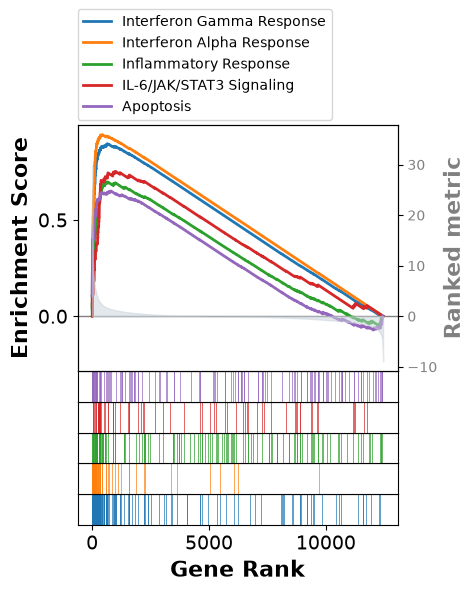

In [49]:
term = nk_res.res2d.Term
axs = nk_res.plot(terms=term[:5])

In [50]:
print("GSEA results for B cells")
b_res = gp.prerank(rnk=b_res_df[['variable', 'stat']], gene_sets="MSigDB_Hallmark_2020")
b_res.res2d.head(5)

2026-10-12 11:32:59,241 [WARNING] Input gene rankings contains NA values(gene name and ranking value), drop them all!


GSEA results for B cells


2026-10-12 11:32:59,307 [WARNING] Duplicated values found in preranked stats: 17.17% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Interferon Alpha Response,0.951662,2.762031,0.0,0.000000,0.000,74/94,2.62%,ISG20;ISG15;B2M;LY6E;UBE2L6;IRF7;IFI35;IFITM2;...
1,prerank,Interferon Gamma Response,0.894190,2.760122,0.0,0.000000,0.000,111/186,4.19%,ISG20;ISG15;B2M;LY6E;UBE2L6;IRF7;IFI35;IFITM2;...
2,prerank,Inflammatory Response,0.688983,2.065480,0.0,0.000349,0.001,43/141,7.83%,LY6E;IRF7;TNFSF10;BST2;EIF2AK2;NMI;CXCL10;SELL...
3,prerank,Complement,0.602241,1.814935,0.0,0.001308,0.005,40/157,9.89%,IRF7;PSMB9;PLSCR1;LAP3;IRF1;CASP4;CASP1;GNB4;I...
4,prerank,Apoptosis,0.599672,1.806989,0.0,0.001255,0.006,24/141,3.68%,ISG20;TNFSF10;SAT1;IFITM3;TAP1;DNAJA1;IRF1;PMA...


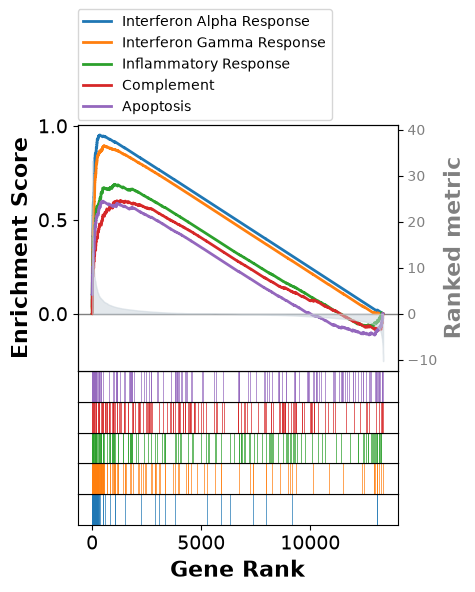

In [51]:
term = b_res.res2d.Term
axs = b_res.plot(terms=term[:5])

---
# Software Versions
Python 3.12.3
- scanpy==1.12.4
- pandas==3.0.6
- seaborn==0.13.2
- anndata==0.13.4
- scipy==1.18.1
- matplotlib==3.11.2
- pertpy==1.4.0
- numpy==2.5.3
- gseapy==1.3.1

In [52]:
from print_versions import print_versions
print("Library Versions")
print_versions(globals())

Library Versions
pandas==3.0.6
scanpy==1.12.4
seaborn==0.13.2
numpy==2.5.3
gseapy==1.3.1
anndata==0.13.4
scipy==1.18.1
matplotlib==3.11.2
pertpy==1.4.0


In [1]:
!python3 --version

Python 3.12.3
